# SEM sources and receivers · positions, types and shots

Where the source is, what kind of source it is, what the receivers record, and how several
shots go into one call. All of it works as on the FD `PropTorch`.

1. Positions: grid indices `[ix, iz]`, fractional allowed
2. Source types: force, explosion and shear source, and their radiation
3. Receiver types: components, derived velocities and the record layout
4. Many shots in one call: per-shot positions and wavelets

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt

from sweep.sem import PropSEM
from sweep.sem.equations import ElasticSEM2DDeformed
from sweep.signal import ricker

device = 'cuda' if torch.cuda.is_available() else 'cpu'
dh, n_order, f0 = 10.0, 4, 10.0
dt = 0.8e-3

## 1. Positions

Sources and receivers are grid indices of the model, `[ix, iz]` in 2-D (`[ix, iy, iz]` in
3-D), as on `PropTorch`; the absorbing layer is outside and has no indices.

| argument | shape | meaning |
| --- | --- | --- |
| `sources` | `(nshots, 2)` | one source per shot |
| `receivers` | `(nshots, nrec, 2)` or `(1, nrec, 2)` | per-shot spreads, or one spread for all shots |
| `wavelet` | `(nt,)` or `(nshots, nt)` | one wavelet for all shots, or one per shot |

An index does not have to be an integer: `[40.5, 20.25]` is a valid source. `PropSEM` finds
the element that holds the point and injects or records through the element's basis
functions. Points inside the absorbing layer are not valid (`PropSEM` warns).

## 2. Source types

On the elastic equations `source_type` takes the `PropTorch` names:

| `source_type` | source | the wavelet is |
| --- | --- | --- |
| `['vz']`, `['vx']` | a point force along z or x (the default is `['vz']`) | the force |
| `['sxx', 'szz']` | an explosion (moment tensor `Mxx = Mzz = 1`) | the moment rate |
| `['sxz']` | a shear source (`Mxz = Mzx = 1`) | the moment rate |

In 3-D the moment tensor has three more names: `['sxx', 'syy', 'szz']` is the explosion,
`['sxy']`, `['sxz']` and `['syz']` the shear sources ([SEM in 3-D](../56_sem_3d/)). On the
acoustic equations the wavelet is the pressure source.

Each source has its own radiation pattern. A snapshot of the displacement 0.25 s after the
wavelet's peak, the source in the middle of a homogeneous model; snapshots need
`impl='eager'` and `return_wavefield=True`:

In [2]:
shape = (121, 121)                           # 1.2 km x 1.2 km, absorbing on all sides
vp  = torch.full(shape, 2000.0, device=device)
vs  = torch.full(shape, 1150.0, device=device)
rho = torch.full(shape, 2000.0, device=device)
nt = 500
delay = 0.12
wavelet = ricker(np.arange(nt) * dt - delay, f=f0).astype(np.float32)
src = np.array([[60, 60]])
rec = np.array([[[60, 100]]])                # one receiver below the source
step = int(round((delay + 0.25) / dt))

snaps = {}
for stype in (['vz'], ['vx'], ['sxx', 'szz'], ['sxz']):
    solver = PropSEM(ElasticSEM2DDeformed, shape=shape, dh=dh, dt=dt, n_order=n_order,
                     abcn=40, f_dominant=f0, source_type=stype,
                     receiver_type=['vx', 'vz'], impl='eager', device=device)
    with torch.no_grad():
        seis, snap = solver(wavelet, src, rec, models=[vp, vs, rho],
                            return_wavefield=True, snapshot_times=[step])
    # (nsnap, nfield, nshots, 1, nz + 2 abcn, nx + 2 abcn): crop the absorbing layer
    snaps[', '.join(stype)] = snap[0, :, 0, 0, 40:-40, 40:-40].numpy()
print('snapshot fields:', solver.snapshot_fields, ' snapshot', tuple(snap.shape))

sweep: torch.compile is compiling the ElasticSEM2DDeformed step for a 121x121 grid; the first call on each new grid size takes seconds to a few minutes (cached on disk for later runs). EagerOptions(use_compile=False) runs uncompiled instead.


snapshot fields: ['u_x', 'u_z']  snapshot (1, 2, 1, 1, 201, 201)


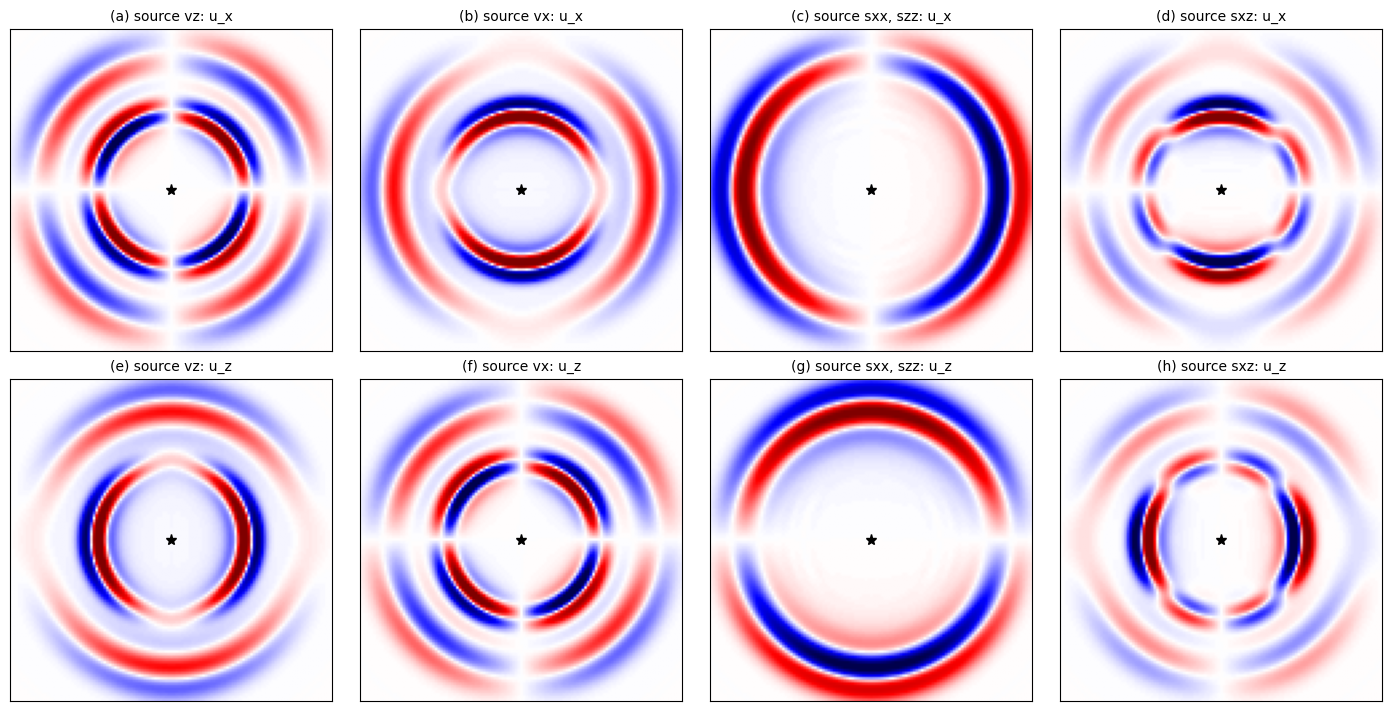

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7), constrained_layout=True)
ext = [0, (shape[1] - 1) * dh, (shape[0] - 1) * dh, 0]
for j, (name, s) in enumerate(snaps.items()):
    for i, comp in enumerate(['u_x', 'u_z']):
        img = s[i]
        lim = np.percentile(np.abs(img[img != 0]), 99)
        ax = axes[i, j]
        ax.imshow(img, cmap='seismic', vmin=-lim, vmax=lim, extent=ext)
        ax.plot(src[0, 0] * dh, src[0, 1] * dh, 'k*', ms=8)
        ax.set_title(f'({"abcdefgh"[4 * i + j]}) source {name}: {comp}', fontsize=10)
        ax.set_xticks([]); ax.set_yticks([])
plt.show()

The outer ring is the P wave, the inner one the S wave. A vertical force sends P mostly up
and down and S mostly sideways, a horizontal force the opposite; the explosion radiates P
only, and the shear source four-lobed P and S.

## 3. Receiver types

`receiver_type` lists the components to record, in the order of the record's last axis. On
the displacement equations (`ElasticSEM2DDeformed`) the fields are `u_x`, `u_z`, and `vx`,
`vz` are their time derivatives; on the velocity-stress ones `vx`, `vz` are the fields. Both
from one run:

record (1, 750, 1, 2) = (nshots, nt, nrec, ncomp), ncomp = ['u_z', 'vz']


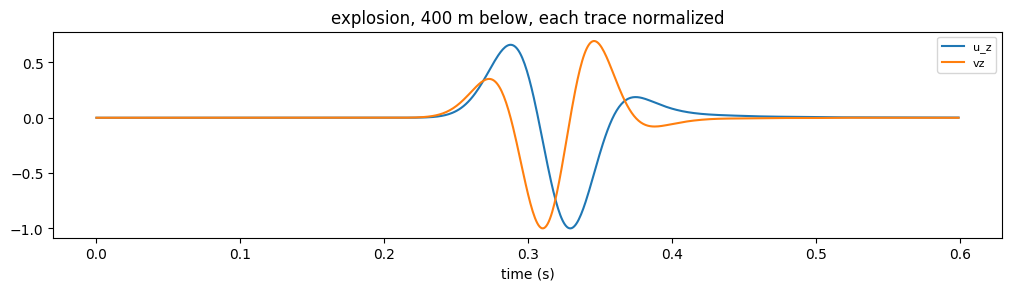

In [4]:
solver = PropSEM(ElasticSEM2DDeformed, shape=shape, dh=dh, dt=dt, n_order=n_order,
                 abcn=40, f_dominant=f0, source_type=['sxx', 'szz'],
                 receiver_type=['u_z', 'vz'], device=device)
nt = 750                                     # long enough for the P wave to pass
wavelet = ricker(np.arange(nt) * dt - delay, f=f0).astype(np.float32)
with torch.no_grad():
    seis = solver(wavelet, src, rec, models=[vp, vs, rho])
print('record', tuple(seis.shape), '= (nshots, nt, nrec, ncomp), ncomp =', solver.receiver_type)

t = np.arange(nt) * dt
uz, vz = seis[0, :, 0, 0].cpu().numpy(), seis[0, :, 0, 1].cpu().numpy()
fig, ax = plt.subplots(figsize=(10, 2.8), constrained_layout=True)
ax.plot(t, uz / np.abs(uz).max(), label='u_z')
ax.plot(t, vz / np.abs(vz).max(), label='vz')
ax.set_xlabel('time (s)'); ax.legend(fontsize=8)
ax.set_title('explosion, 400 m below, each trace normalized')
plt.show()

A receiver can also record the strain `exx`, `ezz`, `exz` and the rotation `rot_y` on the
elastic equations, their rates with `_t` (a horizontal DAS fibre records `exx_t`), and the
pressure `p` on the isotropic ones. On the acoustic potential form `p` is the default
record, and `ux`, `vx`, `ax` (and their `z` components) are the particle displacement,
velocity and acceleration. [Receivers · pressure, particle velocity, rotation, DAS](../47_sem_receivers/)
records them in a marine survey.

## 4. Many shots in one call

Give `sources` one row per shot. Here three shots share one receiver spread (`(1, nrec, 2)`)
and each has its own wavelet (`(3, nt)`), with a different peak frequency. On `impl='c'` the
three shots run as one batched kernel sequence; the record has one gather per shot.

In [5]:
shape = (97, 241)                                    # a two-layer model, free surface
vp  = torch.full(shape, 1800.0); vp[50:]  = 2600.0
vs  = torch.full(shape, 1000.0); vs[50:]  = 1500.0
rho = torch.full(shape, 2000.0); rho[50:] = 2200.0
models = [m.to(device) for m in (vp, vs, rho)]

nt = 1500
sources = np.array([[40, 10], [120, 10], [200, 10]])     # (nshots, 2)
rx = np.arange(0, shape[1], 2)
receivers = np.stack([rx, np.full_like(rx, 1)], axis=1)[None]   # (1, nrec, 2)
freqs = [6.0, 8.0, 10.0]
wavelets = np.stack([ricker(np.arange(nt) * dt - 1.2 / f, f=f) for f in freqs]
                    ).astype(np.float32)                  # (nshots, nt)

solver = PropSEM(ElasticSEM2DDeformed, shape=shape, dh=dh, dt=dt, n_order=n_order,
                 abcn=40, free_surface=True, f_dominant=10.0,
                 source_type=['sxx', 'szz'], receiver_type=['vx', 'vz'], device=device)
with torch.no_grad():
    seis = solver(wavelets, sources, receivers, models=models)
print('sources', sources.shape, ' receivers', receivers.shape, ' wavelets', wavelets.shape)
print('record', tuple(seis.shape), ' impl', solver.impl)

sources (3, 2)  receivers (1, 121, 2)  wavelets (3, 1500)
record (3, 1500, 121, 2)  impl c


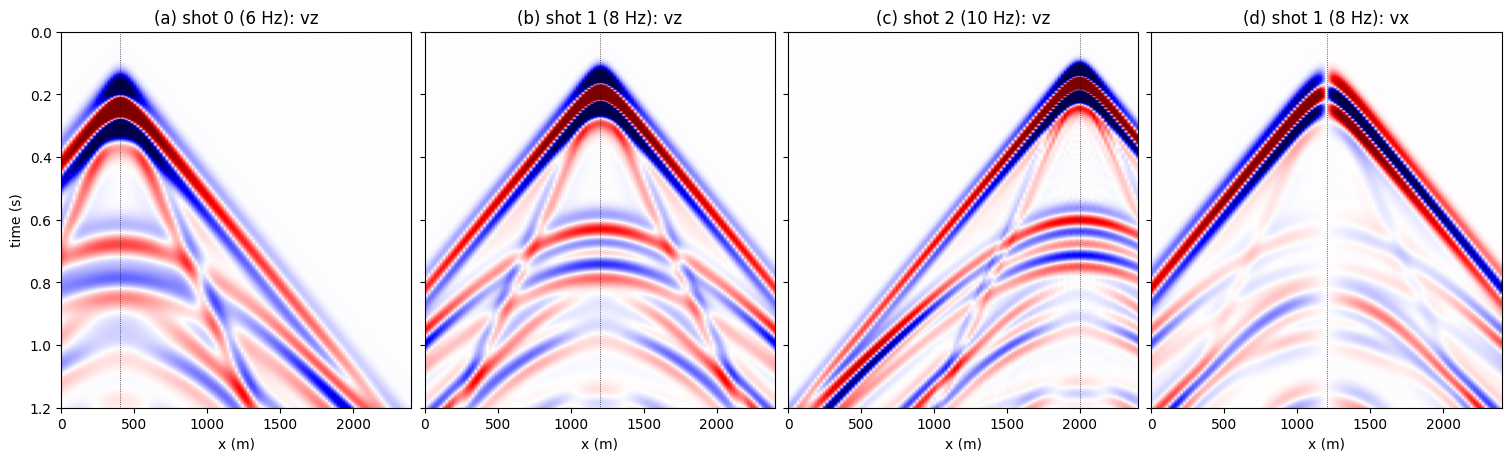

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(15, 4.5), sharey=True, constrained_layout=True)
ext = [rx[0] * dh, rx[-1] * dh, nt * dt, 0]
panels = [(0, 1, '(a) shot 0 (6 Hz): vz'), (1, 1, '(b) shot 1 (8 Hz): vz'),
          (2, 1, '(c) shot 2 (10 Hz): vz'), (1, 0, '(d) shot 1 (8 Hz): vx')]
for ax, (s, c, title) in zip(axes, panels):
    g = seis[s, :, :, c].cpu().numpy()
    lim = np.percentile(np.abs(g[g != 0]), 98)
    ax.imshow(g, cmap='seismic', vmin=-lim, vmax=lim, aspect='auto', extent=ext)
    ax.axvline(sources[s, 0] * dh, color='k', lw=0.5, ls=':')
    ax.set_title(title); ax.set_xlabel('x (m)')
axes[0].set_ylabel('time (s)')
plt.show()

## Summary

- `sources` `(nshots, ndim)`, `receivers` `(nshots, nrec, ndim)` or `(1, nrec, ndim)`,
  `wavelet` `(nt,)` or `(nshots, nt)`; indices `[ix, iz]` of the model grid,
  fractional allowed.
- `source_type`: `['vz']` / `['vx']` force, `['sxx', 'szz']` explosion, `['sxz']`
  shear (elastic; in 3-D also `syy`, `sxy`, `syz`); on the acoustic equations the
  wavelet is the pressure source.
- `receiver_type`: any of the equation's receiver fields, the derived `vx`, `vz`
  and `p`, and the strain and rotation receivers; the record is
  `(nshots, nt, nrec, len(receiver_type))`.

Next: [SEM boundaries · the C-PML, free surfaces and snapshots](../53_sem_boundaries_and_snapshots/).

---

<p><strong>Download this notebook</strong> &mdash; <a href="52_sem_sources_and_receivers.ipynb" download><code>52_sem_sources_and_receivers.ipynb</code></a> &middot; or <a href="https://github.com/DeepWave-KAUST/sweep/blob/dev/docs/notebooks/52_sem_sources_and_receivers.ipynb">view on GitHub</a></p>